# Inference grid

This notebook prepares the input locations for inference/test time. 

- The grid is based on the Bedmap 500m grid.
- We subset only on-land gridpoints with a mask.
- We exclude rock outcrops.
- We exclude the very low ice flux area > 300_000 km PS in x direction, as done in Steward et al. 2019.

Note: y, x order

## 1. Load data

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import torch
import matplotlib.pyplot as plt

In [2]:
path_to_bedmap = "/Users/kim.bente/DATA/bedmap/bedmap3.nc"
bedmap = xr.load_dataset(path_to_bedmap)

## 2. Crop to general region

In [3]:
# import region bounds
from regions import ROSS_ISLAND_BOUNDS

# assign region bounds
x_min = ROSS_ISLAND_BOUNDS["x_min"]
x_max = ROSS_ISLAND_BOUNDS["x_max"]
y_min = ROSS_ISLAND_BOUNDS["y_min"]
y_max = ROSS_ISLAND_BOUNDS["y_max"]

print("Region span:", x_max - x_min, "x", y_max - y_min)

Region span: 200000 x 180000


In [4]:
# Subset for Ross Island region
bedmap = bedmap.sel(
    x = slice(x_min, x_max),
    y = slice(y_max, y_min) # Note: y_max and y_min are reversed because y decreases southward in polar stereographic coordinates
)

## 3. Extract full square set of locations

In [5]:
# Broadcast / meshgrid
Y, X = xr.broadcast(bedmap.y, bedmap.x)
print("X values shape:", X.values.shape)
print("Y values shape:", Y.values.shape)

# Flatten
Y_long = Y.values.flatten()
X_long = X.values.flatten()
print("X_long shape:", X_long.shape)
print("Y_long shape:", Y_long.shape)

# Normalise
X_long_norm = (X_long - x_min) / (x_max - x_min)
Y_long_norm = (Y_long - y_min) / (y_max - y_min)

# Make long tensor: XY order needed for model input
XY_long_tensor = torch.cat((
    torch.tensor(X_long_norm).unsqueeze(1), 
    torch.tensor(Y_long_norm).unsqueeze(1),
    ), dim = 1)

print("XY_long_tensor shape:", XY_long_tensor.shape)

# Export tensor for inference
torch.save(XY_long_tensor, "data/XY_long_tensor.pt")

X values shape: (360, 400)
Y values shape: (360, 400)
X_long shape: (144000,)
Y_long shape: (144000,)
XY_long_tensor shape: torch.Size([144000, 2])


## 3. Generate grounded ice mask

1 or True indicates the grid cells we wish to keep.

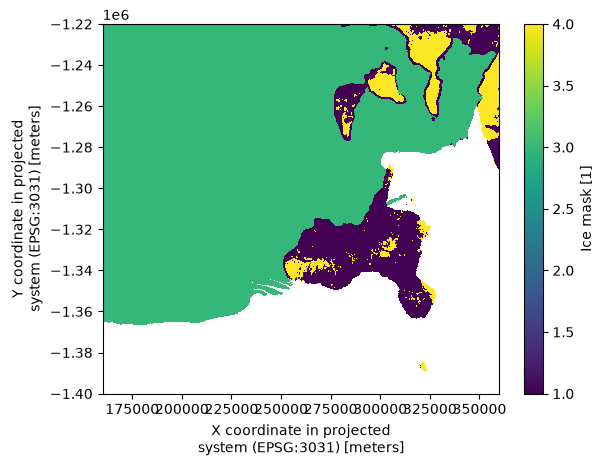

In [6]:
bedmap.mask.plot()
# Note: Mask value 3 is what we want

In [7]:
grounded_ice_mask_np = (bedmap.mask == 3)
# make tensor
grounded_ice_mask = torch.tensor(grounded_ice_mask_np.values)

print("Grounded ice mask shape:", grounded_ice_mask.shape)
grounded_ice_mask

Grounded ice mask shape: torch.Size([360, 400])


tensor([[ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        ...,
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False]])

## 4. Mask out > 300_000

In [8]:
east_mask = (X.values <= 300_000)

east_mask_tensor = torch.tensor(east_mask)
east_mask_tensor

tensor([[ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        ...,
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False]])

## 5. Combine both masks

Include only if both are true

In [9]:
combined_mask = east_mask_tensor & grounded_ice_mask

print("Number of valid points in combined mask:", combined_mask.sum().item())
print("Number of valid points in east mask:", east_mask_tensor.sum().item())
print("Number of valid points in grounded ice mask:", grounded_ice_mask.sum().item())

# Export combined mask for inference
torch.save(combined_mask, "data/combined_mask.pt")

Number of valid points in combined mask: 69385
Number of valid points in east mask: 100800
Number of valid points in grounded ice mask: 77885


## 6. Further exclude grid cells away from training data

In [10]:
bedmap.mask

<xarray.DataArray 'mask' (y: 360, x: 400)> Size: 576kB
array([[ 3.,  3.,  3., ...,  1.,  1.,  1.],
       [ 3.,  3.,  3., ...,  1.,  1.,  1.],
       [ 3.,  3.,  3., ...,  1.,  1.,  1.],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(360, 400), dtype=float32)
Coordinates:
  * y        (y) float32 1kB -1.22e+06 -1.221e+06 ... -1.399e+06 -1.4e+06
  * x        (x) float32 2kB 1.602e+05 1.608e+05 ... 3.592e+05 3.598e+05
Attributes:
    units:          1
    long_name:      Ice mask
    description:    Categorization of surface type based on grounding status:...
    flag_values:    [1 2 3 4]
    flag_meanings:  grounded_ice transiently_grounded_ice_shelf floating_ice_...
    grid_mapping:   mapping

In [11]:
import numpy as np
from scipy import ndimage

nan_mask = np.isnan(bedmap.mask.values)

dist = ndimage.distance_transform_edt( ~ nan_mask)           # cells to nearest NaN
dist_smooth = ndimage.gaussian_filter(dist, sigma = 5)       # larger sigma = smoother
near_nan = dist_smooth <= 12

mask_eroded = bedmap.mask.where(~ near_nan)

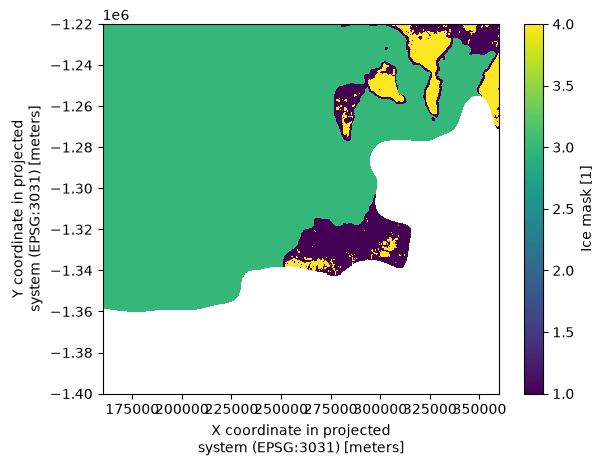

In [12]:
mask_eroded.plot()

In [13]:
smoothed_grounded_ice_mask_np = (mask_eroded == 3)
# make tensor
smoothed_grounded_ice_mask = torch.tensor(smoothed_grounded_ice_mask_np.values)

print("Smoothed grounded ice mask shape:", smoothed_grounded_ice_mask.shape)
smoothed_grounded_ice_mask

Smoothed grounded ice mask shape: torch.Size([360, 400])


tensor([[ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        ...,
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False]])

In [14]:
stricter_combined_mask = east_mask_tensor & smoothed_grounded_ice_mask

print("Number of valid points in east mask:", east_mask_tensor.sum().item())
print("Number of valid points in stricter combined mask:", stricter_combined_mask.sum().item())

# Export combined mask for inference
torch.save(stricter_combined_mask, "data/stricter_combined_mask.pt")

Number of valid points in east mask: 100800
Number of valid points in stricter combined mask: 66273
